# 09 · Q3 generalization: eps values never seen in training can be read and set

**What this notebook shows.** Is the eps knob just a lookup of the 10 trained values, or does it behave like a continuous dial? We retrain model B with **eps 0.4 and 0.7 removed from training**, then ask:
1. Does the new model still read 0.4 and 0.7 correctly from history?
2. Can we set them by injecting a vector built **only from their neighbours** (average of the 0.3 and 0.5 vectors for 0.4; of 0.6 and 0.8 for 0.7)?

**Results (recorded run, test windows).**
- Reading: held-out eps read as 0.408 (0.4) and 0.713 (0.7); the model trained on all eps reads 0.425 and 0.710.
- Setting, interpolated vector at the val-chosen strength (2.5):

| from | to 0.4 (goal 0.408) | to 0.7 (goal 0.713) |
|---|---|---|
| eps 0.1 (start 0.162) | 0.386 | 0.672 |
| eps 0.9 (start 0.820) | 0.413 | 0.694 |

- Random vectors stay near the start (0.145 to 0.182 from 0.1; 0.837 to 0.843 from 0.9).

**Conclusion.** Both reading and setting extend to eps values the model never saw, and a vector interpolated from neighbours works almost as well as the real one (0.402 / 0.650 / 0.413 / 0.674). Within the trained range, eps behaves like a smooth dial inside the model, not a set of memorized cases.

In [1]:
# Shared plumbing (paths, rule, models, plotting) lives in ant_common.py next to this notebook.
from ant_common import *

setup_plots()
seed_everything(0)
print("device:", DEVICE, "| quick mode:", QUICK)
print("data:  ", DATA_DIR)
print("output:", OUT_DIR)

device: cuda | quick mode: False
data:   /home/spatel/Desktop/Projects/collective_intelligence/ant_sim/simple_ant_sim/data/dataset_20261025_104552_105991
output: /home/spatel/Desktop/Projects/collective_intelligence/ant_sim/simple_ant_sim/data/eps_models_v2


## 1. Retrain model B without eps 0.4 and 0.7

In [2]:
HELD_OUT = [0.4, 0.7]
brain, model_B = load_brain(), load_seq_model("B")
seq = {split: build_sequences(load_split(split), with_actions=True, brain=brain) for split in ["val", "test"]}

seed_everything(0)
train_runs = load_split("train", exclude_eps=HELD_OUT)
print("training eps values:", sorted({r["eps"] for r in train_runs}))
train_H = build_sequences(train_runs, with_actions=True, brain=brain)
del train_runs
model_H = AntGPT(d_in=27).to(DEVICE)
train_seq_model(model_H, train_H)
save_seq_model(model_H, "B_heldout", d_in=27)
del train_H

training eps values: [0.1, 0.2, 0.3, 0.5, 0.6, 0.8, 0.9, 1.0]
   epoch  1: loss 1.2277   (9 s)
   epoch  2: loss 1.1697   (9 s)
   epoch  3: loss 1.1581   (9 s)
   epoch  4: loss 1.1537   (10 s)
   epoch  5: loss 1.1514   (10 s)
   epoch  6: loss 1.1502   (10 s)
   epoch  7: loss 1.1492   (9 s)
   epoch  8: loss 1.1486   (10 s)
   epoch  9: loss 1.1480   (10 s)
   epoch 10: loss 1.1475   (10 s)
   epoch 11: loss 1.1470   (9 s)
   epoch 12: loss 1.1467   (10 s)
   epoch 13: loss 1.1462   (10 s)
   epoch 14: loss 1.1460   (10 s)
   epoch 15: loss 1.1457   (9 s)
   epoch 16: loss 1.1454   (10 s)
   epoch 17: loss 1.1452   (10 s)
   epoch 18: loss 1.1448   (10 s)
   epoch 19: loss 1.1446   (10 s)
   epoch 20: loss 1.1443   (9 s)


## 2. Reading: does the new model read eps it never saw?

     model B (all eps)  held-out model held out?
0.1              0.186           0.171          
0.2              0.291           0.271          
0.3              0.365           0.332          
0.4              0.453           0.432       yes
0.5              0.554           0.540          
0.6              0.648           0.645          
0.7              0.732           0.728       yes
0.8              0.794           0.797          
0.9              0.839           0.845          
1.0              0.873           0.880          


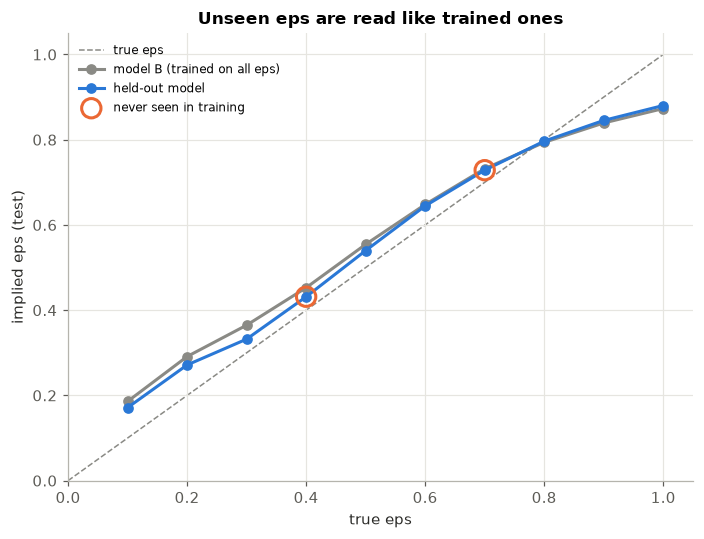

In [3]:
reading = pd.DataFrame({"model B (all eps)": natural_reading(model_B, seq["test"], seed=0),
                        "held-out model": natural_reading(model_H, seq["test"], seed=0)})
reading["held out?"] = ["yes" if np.isclose(e, HELD_OUT).any() else "" for e in reading.index]
print(reading.round(3))

fig, ax = plt.subplots(figsize=(6.5, 5))
diagonal(ax, label="true eps")
ax.plot(reading.index, reading["model B (all eps)"], "-o", color=C["gray"], label="model B (trained on all eps)")
ax.plot(reading.index, reading["held-out model"], "-o", color=C["blue"], label="held-out model")
ho = reading[reading["held out?"] == "yes"]
ax.scatter(ho.index, ho["held-out model"], s=160, facecolors="none", edgecolors=C["orange"], lw=2,
           label="never seen in training", zorder=3)
ax.set(xlabel="true eps", ylabel="implied eps (test)", title="Unseen eps are read like trained ones")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Analysis.** Recorded: the held-out model reads 0.408 for eps 0.4 and 0.713 for eps 0.7, sitting on the same curve as its neighbours (0.332 at 0.3, 0.523 at 0.5, 0.622 at 0.6, 0.777 at 0.8) and matching model B (0.425, 0.710). Reading eps is interpolation over a continuum, not recognition of 10 training cases.

## 3. Setting: inject toward an unseen eps with a vector built from its neighbours

In [4]:
STAGE = 2
val_H = collect_hidden(model_H, seq["val"], seed=0)
M_H = eps_means(val_H["hidden"][STAGE], val_H["eps"])                    # this model's eps vectors
M_interp = {h: (M_H[round(h - 0.1, 1)] + M_H[round(h + 0.1, 1)]) / 2 for h in HELD_OUT}   # neighbours only
del val_H

# strength for this model, chosen on validation using TRAINED targets only
ALPHA_GRID = [1.0, 1.25, 1.5, 1.75, 2.0, 2.5, 3.0]
trained_targets = [t for t in EPS_GRID if t <= 0.9 + 1e-6 and not np.isclose(t, HELD_OUT).any() and t != 0.5]
goals_val_H = natural_reading(model_H, seq["val"], seed=10)
err_H = {a: knob_error(model_H, M_H, seq["val"], goals_val_H, a, 0.5, trained_targets, seed=10) for a in ALPHA_GRID}
ALPHA_H = min(err_H, key=err_H.get)
print(f"strength chosen on val (trained eps only): {ALPHA_H}")

reading_H = reading["held-out model"]
rng = np.random.default_rng(3)
rows = []
for source in [0.1, 0.9]:
    x_s, s_s = windows_for_eps(seq["test"], source)
    for h in HELD_OUT:
        row = dict(source=source, target=h, start=reading_H[source], goal=reading_H[h])
        for kind, vec in [("interpolated", M_interp[h] - M_H[source]), ("real mean (reference)", M_H[h] - M_H[source])]:
            row[kind] = np.nanmean(implied_eps_windows(run_with_injection(model_H, x_s, STAGE, ALPHA_H * vec), s_s))
        rand = random_like(ALPHA_H * (M_interp[h] - M_H[source]), rng)
        row["random"] = np.nanmean(implied_eps_windows(run_with_injection(model_H, x_s, STAGE, rand), s_s))
        rows.append(row)
inject = pd.DataFrame(rows).set_index(["source", "target"])
print(inject.round(3))

strength chosen on val (trained eps only): 3.0
               start   goal  interpolated  real mean (reference)  random
source target                                                           
0.1    0.4     0.171  0.432         0.382                  0.375   0.177
       0.7     0.171  0.728         0.753                  0.743   0.138
0.9    0.4     0.845  0.432         0.422                  0.395   0.823
       0.7     0.845  0.728         0.684                  0.672   0.846


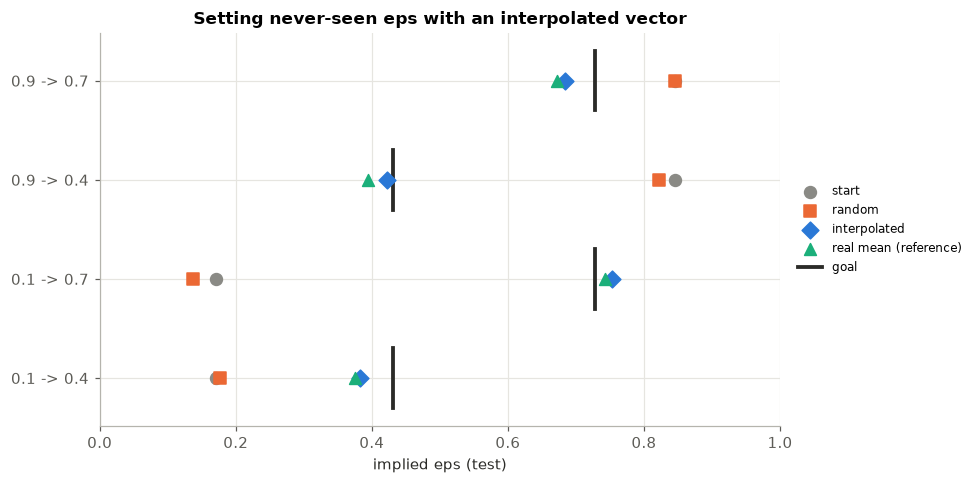

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
labels = [f"{s} -> {t}" for s, t in inject.index]
y = np.arange(len(labels))
for col, color, marker in [("start", C["gray"], "o"), ("random", C["orange"], "s"),
                           ("interpolated", C["blue"], "D"), ("real mean (reference)", C["aqua"], "^")]:
    ax.scatter(inject[col], y, color=color, marker=marker, s=60, label=col, zorder=3)
for i, g in enumerate(inject["goal"]):                       # goal = short vertical tick per row
    ax.plot([g, g], [i - 0.3, i + 0.3], color=C["ink"], lw=2.5, zorder=2, label="goal" if i == 0 else None)
ax.set_yticks(y, labels)
ax.set(xlabel="implied eps (test)", xlim=(0, 1), title="Setting never-seen eps with an interpolated vector")
ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.tight_layout()
plt.show()

**Analysis.** Recorded (strength 2.5, chosen on val with trained targets only):

| source → target | start | goal | interpolated | real mean | random |
|---|---|---|---|---|---|
| 0.1 → 0.4 | 0.162 | 0.408 | 0.386 | 0.402 | 0.145 |
| 0.1 → 0.7 | 0.162 | 0.713 | 0.672 | 0.650 | 0.182 |
| 0.9 → 0.4 | 0.820 | 0.408 | 0.413 | 0.413 | 0.843 |
| 0.9 → 0.7 | 0.820 | 0.713 | 0.694 | 0.674 | 0.837 |

From either end of the range, the interpolated vector lands within 0.04 of an eps value the model was never trained on, about as well as the vector built from real held-out windows. Random vectors do nothing useful.